## Cleaning Data

### Converting applicable columns into Int or Float types, and leaving IDs in string formats

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from matplotlib.lines import Line2D

In [2]:
selected_census_data = pd.read_csv("/home/jovyan/cityplanning_proj/selected_census_data")

# Rename columns from API call
rename_map = {
    "NAME": "tract_name",
    "B03002_001E": "total_pop", "B03002_003E": "nh_white", "B03002_004E": "nh_black",
    "B03002_005E": "nh_aian", "B03002_006E": "nh_asian", "B03002_007E": "nh_nhpi",
    "B03002_008E": "nh_other_race", "B03002_009E": "nh_two_or_more", "B03002_012E": "hispanic_latino",
    "B01002_001E": "median_age", "B09001_001E": "pop_under_18",
    "B01001_020E": "male_65_66", "B01001_021E": "male_67_69", "B01001_022E": "male_70_74",
    "B01001_023E": "male_75_79", "B01001_024E": "male_80_84", "B01001_025E": "male_85_plus",
    "B01001_044E": "female_65_66", "B01001_045E": "female_67_69", "B01001_046E": "female_70_74",
    "B01001_047E": "female_75_79", "B01001_048E": "female_80_84", "B01001_049E": "female_85_plus",
    "B19013_001E": "median_hh_income", "B19113_001E": "median_family_income", "B19301_001E": "per_capita_income",
    "C17002_001E": "poverty_universe", "C17002_002E": "ratio_u050", "C17002_003E": "ratio_050_099",
    "C17002_004E": "ratio_100_124", "C17002_005E": "ratio_125_149", "C17002_006E": "ratio_150_184",
    "C17002_007E": "ratio_185_199",
    "B22003_002E": "hh_snap",
    "B08201_001E": "total_hh", "B08201_002E": "hh_veh_0", "B08201_003E": "hh_veh_1",
    "B08201_004E": "hh_veh_2", "B08201_005E": "hh_veh_3", "B08201_006E": "hh_veh_4plus",
    "B25046_001E": "aggregate_vehicles", "B25010_001E": "avg_hh_size",
    "B08301_001E": "total_workers", "B08301_010E": "workers_transit",
    "B08301_019E": "workers_walk", "B08301_021E": "workers_wfh",
    }

# column groups (for ACS ones)
acs_cols   = [v for k, v in rename_map.items() if k != "NAME" and v in selected_census_data.columns]
float_cols = [c for c in acs_cols if c in ("median_age", "avg_hh_size")]
int_cols   = [c for c in acs_cols if c not in float_cols]

# strings to numbers (sentinel codes stay as nums)
selected_census_data[acs_cols] = selected_census_data[acs_cols].apply(pd.to_numeric, errors="coerce")

# converting to the dtypes
selected_census_data[int_cols]   = selected_census_data[int_cols].astype("Int64")
selected_census_data[float_cols] = selected_census_data[float_cols].astype("float64")

# keeping IDs as str
selected_census_data["geoid"]    = selected_census_data["geoid"].astype(str).str.zfill(11)
selected_census_data["county"] = selected_census_data["county"].astype(str).str.zfill(3)
selected_census_data["state"]    = selected_census_data["state"].astype(str).str.zfill(11)
selected_census_data["tract"]    = selected_census_data["tract"].astype(str).str.zfill(11)

# checking for nulls
print(selected_census_data[acs_cols].isna().sum().loc[lambda s: s > 0])

aggregate_vehicles    24
dtype: int64


In [3]:
selected_census_data[selected_census_data.total_pop == 0]

,tract_name,total_pop,nh_white,nh_black,nh_aian,nh_asian,nh_nhpi,nh_other_race,nh_two_or_more,hispanic_latino,...,total_workers,workers_transit,workers_walk,workers_wfh,state,county,tract,geoid,countyfp,geometry
324,Census Tract 4443.03; Alameda County; California,0,0,0,0,0,0,0,0,0,...,0,0,0,0,00000000006,001,00000444303,6001444303.0,1.0,MULTIPOLYGON (((-122.10179291503596 37.5177463...
378,Census Tract 9900; Alameda County; California,0,0,0,0,0,0,0,0,0,...,0,0,0,0,00000000006,001,00000990000,6013990000.0,13.0,POLYGON ((-122.40910999965438 37.9206999999330...
620,Census Tract 9900; Contra Costa County; Califo...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,00000000006,013,00000990000,6013990000.0,13.0,POLYGON ((-122.40910999965438 37.9206999999330...
859,Census Tract 9804.01; San Francisco County; Ca...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,00000000006,075,00000980401,6075980401.0,75.0,MULTIPOLYGON (((-123.00055999994889 37.6951400...
863,Census Tract 9901; San Francisco County; Calif...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,00000000006,075,00000990100,00000000nan,NaN,NaN
864,Census Tract 9902; San Francisco County; Calif...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,00000000006,075,00000990200,6075990200.0,75.0,MULTIPOLYGON (((-122.32785034320709 37.7810815...


### Keeping relevant tracts & columns
- 6 Census tracts with no population - AC: 444303, 990000, CC: 990000, SF: 980401, 990100, 990200
- Drop from analysis since our focus is on food deserts that directly affect people
- Columns 'county' & 'countyfp' are redundant from above join, so will drop 'countyfp'

In [4]:
new_df = selected_census_data[selected_census_data["total_pop"] > 0].drop(columns=['countyfp'])

In [5]:
# checking for dtype, missing values, and getting a basic summary of data

print(new_df.info())
print()
print('Missing values per column:')
print(new_df.isna().sum())
print()
print('Summary of the numeric columns:')
print(new_df[['total_pop', 'median_hh_income','per_capita_income', 'aggregate_vehicles']].describe())

<class 'pandas.core.frame.DataFrame'>
Index: 859 entries, 0 to 862
Data columns (total 52 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   tract_name            859 non-null    object 
 1   total_pop             859 non-null    Int64  
 2   nh_white              859 non-null    Int64  
 3   nh_black              859 non-null    Int64  
 4   nh_aian               859 non-null    Int64  
 5   nh_asian              859 non-null    Int64  
 6   nh_nhpi               859 non-null    Int64  
 7   nh_other_race         859 non-null    Int64  
 8   nh_two_or_more        859 non-null    Int64  
 9   hispanic_latino       859 non-null    Int64  
 10  median_age            859 non-null    float64
 11  pop_under_18          859 non-null    Int64  
 12  male_65_66            859 non-null    Int64  
 13  male_67_69            859 non-null    Int64  
 14  male_70_74            859 non-null    Int64  
 15  male_75_79            859 no

### Creating a flag for sentinel codes, and a cleaned df for visualizations (without NaN)

In [6]:
# for estimates cols (sentinels): 
# -666666666 is too few est-> NaN, 
# -999999999 -> insuff to dispaly -> NaN,
# -888888888 -> not avail -> NaN

# ACS columns (one contiguous block in table)
acs_cols = new_df.loc[:, "total_pop":"workers_wfh"].columns

# float copy of those columns, so plain NaN (keeps sentinel codes)
vals = new_df[acs_cols].astype("float64")

# True if has sentinel codes:(-666666666, -999999999, -888888888, -222222222, -333333333, -555555555)
is_sent = vals < -1e8

# adds flag columns are added
new_df["has_sentinel"]    = is_sent.any(axis=1)                      # row has at least one sentinel
new_df["income_topcoded"] = vals["median_hh_income"] == 250001       # value is real, tho is capped at "$250,000 or more"

# visualization tbl- sentinels are NaN
viz = new_df.copy()
viz[acs_cols] = vals.mask(is_sent)         # NaN = unknown, drawn in gray with missing_kwds

# estimates aggregate_vehicles from the household vehicle columns (is approximate, because the 4+ col is exactly 4)
est = viz['hh_veh_1'] + 2*viz['hh_veh_2'] + 3*viz['hh_veh_3'] + 4*viz['hh_veh_4plus']
gap = viz.aggregate_vehicles.isna() & est.notna() & (viz.total_hh > 0)
viz.loc[gap, "aggregate_vehicles"] = est[gap]
viz["vehicles_estimated"] = gap            # flag so estimated val are not mistaken for real

# checking for the NaN values in viz
print(viz[acs_cols].isna().sum().loc[lambda s: s > 0])            

median_hh_income        10
median_family_income    21
aggregate_vehicles       2
avg_hh_size              2
dtype: int64


In [7]:
print(viz[['total_pop', 'median_hh_income','per_capita_income']].describe())

         total_pop  median_hh_income  per_capita_income
count    859.00000        849.000000         859.000000
mean    4242.98021     140150.085984       73585.722934
std     1688.62390      56732.281779       35848.238123
min       33.00000      12908.000000        8422.000000
25%     3058.50000      97417.000000       46250.500000
50%     4028.00000     134211.000000       68075.000000
75%     5257.00000     179194.000000       93292.000000
max    12378.00000     250001.000000      250455.000000


#### Basic Summary Statistics
- Avg tract population size is 4243 people, min: 33, max: 12378
- Avg median household income is $140150, min 12,908, max: 250001 (max is top-coded 250,000+)

- Avg per capita income is $73586, min 8422, max: 250455

- NaN values in aggregate columns

## Creating Visualizations/Charts

In [8]:
# change crs, map names of counties
names = {"001": "Alameda", "013": "Contra Costa", "075": "San Francisco"}
viz["geometry"] = gpd.GeoSeries.from_wkt(viz["geometry"])
viz = gpd.GeoDataFrame(viz, geometry="geometry", crs="EPSG:4326").to_crs(epsg=3310)
viz["county_name"] = viz["county"].map(names)

# measures percents for the plots (NaN where a denom is 0/value is suppressed)
pct = lambda n, d: 100 * n / d.where(d > 0)
below200 = ["ratio_u050", "ratio_050_099", "ratio_100_124", "ratio_125_149", "ratio_150_184", "ratio_185_199"]
viz["pct_no_vehicle"]    = pct(viz.hh_veh_0, viz.total_hh)
viz["pct_snap"]          = pct(viz.hh_snap, viz.total_hh)
viz["pct_below_200fpl"]  = pct(viz[below200].sum(axis=1, min_count=6), viz.poverty_universe)

### Choropleths: 

Mapping out
- % households with no vehicle
- % below 200% of poverty
- % receiving SNAP
- median household income

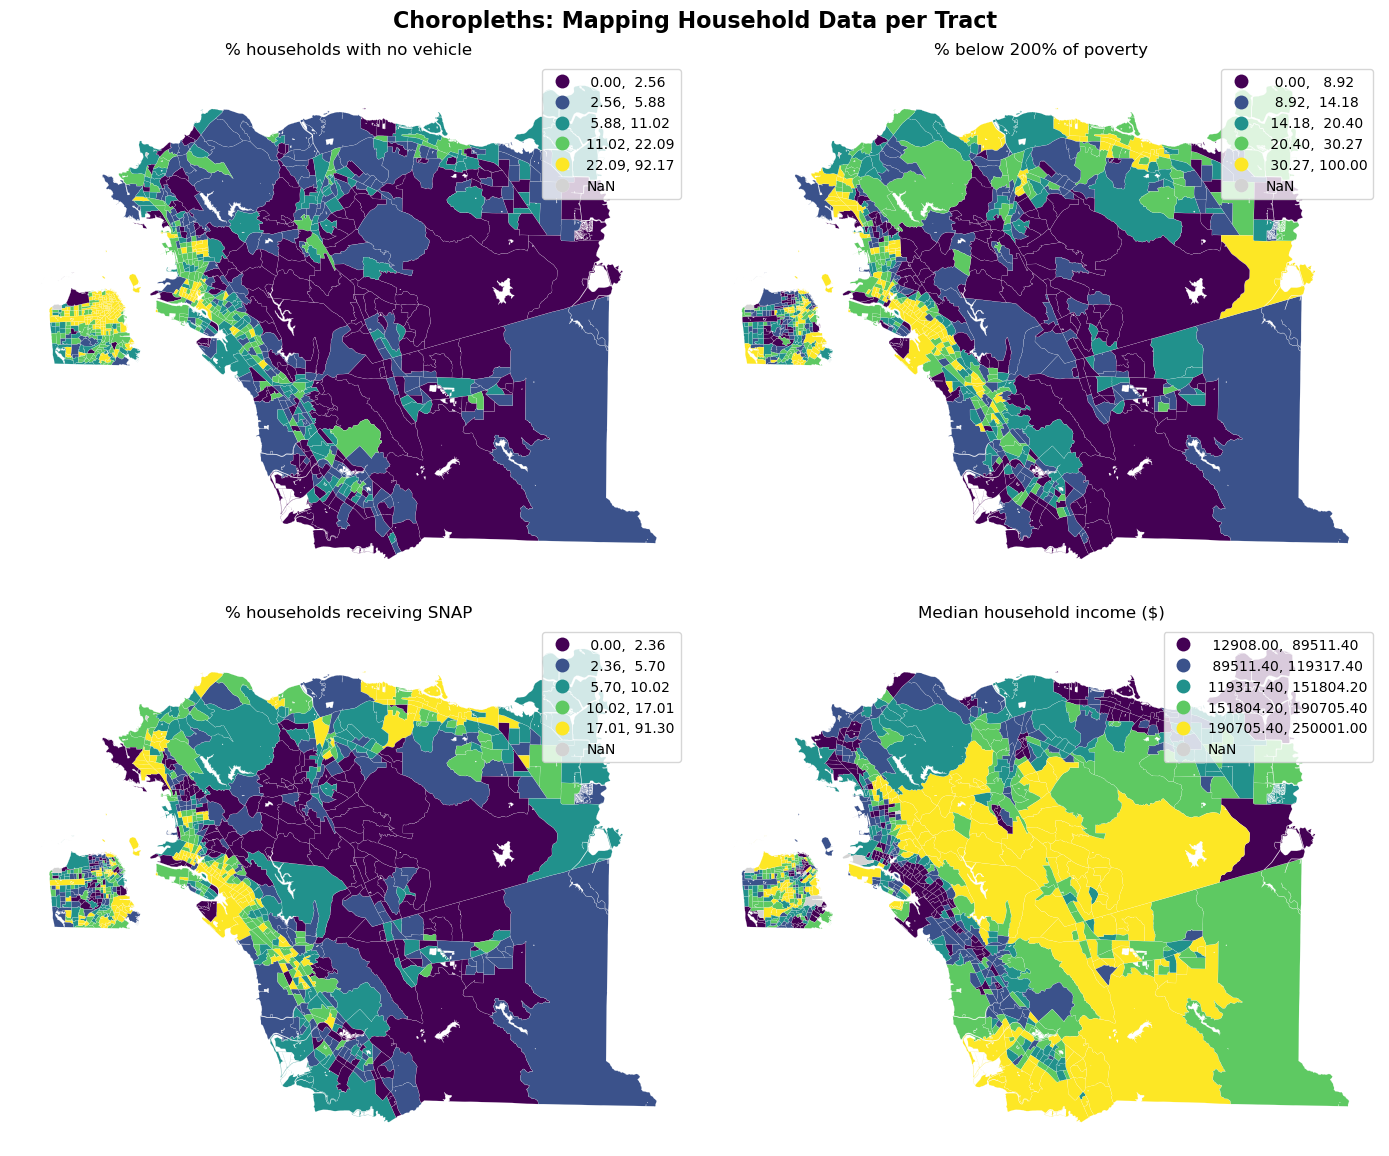

In [9]:
# Choropleth (gray = no reliable data)
maps = {"pct_no_vehicle": "% households with no vehicle", "pct_below_200fpl": "% below 200% of poverty",
        "pct_snap": "% households receiving SNAP", "median_hh_income": "Median household income ($)"}
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (col, title) in zip(axes.flat, maps.items()):
    viz.plot(column=col, cmap="viridis", scheme="quantiles", k=5, legend=True, ax=ax,
           linewidth=0.1, edgecolor="white", missing_kwds={"color": "lightgray"})
    ax.set_title(title); ax.set_axis_off()
plt.suptitle("Choropleths: Mapping Household Data per Tract", fontsize= 16, fontweight= "bold")
plt.tight_layout()

### County Racial Demographics 
- Demographic level charts might not be as applicable right now for analysis, until we target relevant tracts and then look for any racial disparities or mobility related issues

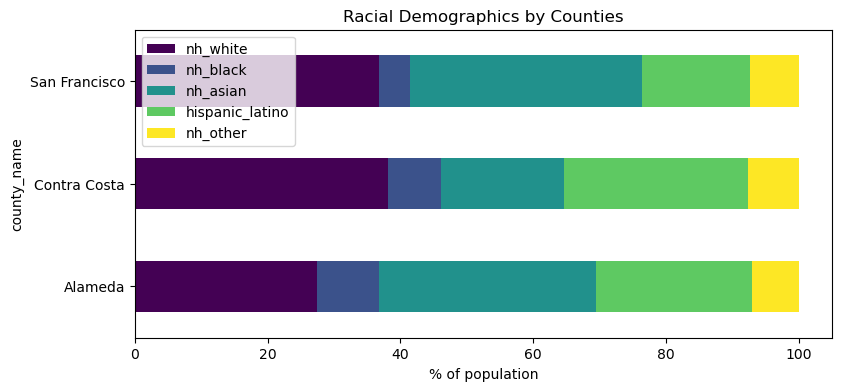

In [10]:
viz["nh_other"] = viz[["nh_aian", "nh_nhpi", "nh_other_race", "nh_two_or_more"]].sum(axis=1)
comp = viz.groupby("county_name")[["nh_white", "nh_black", "nh_asian", "hispanic_latino", "nh_other"]].sum()
(100 * comp.div(comp.sum(axis=1), axis=0)).plot(kind="barh", cmap="viridis",stacked=True, figsize=(9, 4))
plt.xlabel("% of population")
plt.title("Racial Demographics by Counties")
plt.show()

### No vehicle vs SNAP Scatter Plot 
- bubble size corresponds to tract population
- dashed lines at 75th percentile to highlight top right quadrant where there is high SNAP & low car access

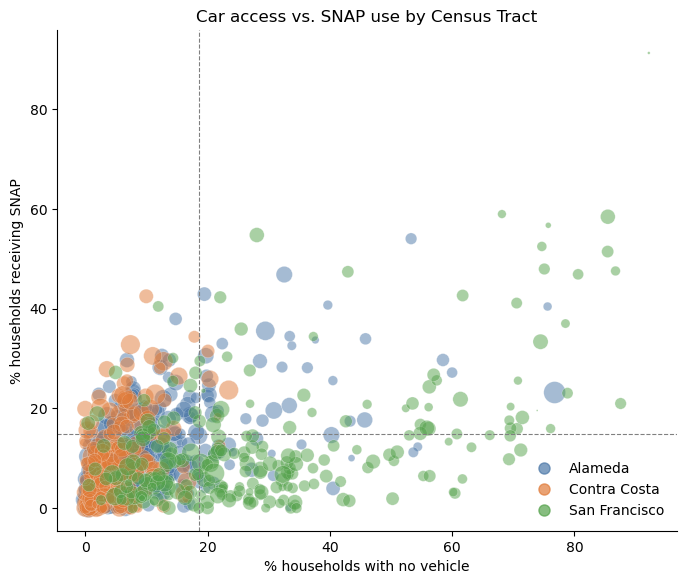

In [11]:
colors = {"Alameda": "#4c78a8", "Contra Costa": "#e07b39", "San Francisco": "#54a24b"}
viz["pct_transit"] = 100 * viz["workers_transit"] / viz["total_workers"].where(viz["total_workers"] > 0)

fig, ax = plt.subplots(figsize=(8, 6.5))
for name, g in viz.groupby("county_name"):
    ax.scatter(g["pct_no_vehicle"], g["pct_snap"], s=g["total_pop"] / 40, alpha=0.5,
               color=colors[name], edgecolor="white", linewidth=0.3)

# top-right is high SNAP & low car access
ax.axvline(viz["pct_no_vehicle"].quantile(0.75), color="gray", ls="--", lw=0.8)
ax.axhline(viz["pct_snap"].quantile(0.75), color="gray", ls="--", lw=0.8)

ax.set_xlabel("% households with no vehicle")
ax.set_ylabel("% households receiving SNAP")
ax.set_title("Car access vs. SNAP use by Census Tract")
ax.legend(handles=[Line2D([0], [0], marker="o", ls="", color=c, label=n, markersize=8, alpha=0.7)
                   for n, c in colors.items()], frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Top right quadrant highlights attention on where there is a high percent of households with no vehicle and that receive SNAP, specifically the tracts in Alameda and SF. 

Note: might help to make this chart interactive in the future, since it could help identify each tract and its characteristics as well. 